# Домашнее задание 4: Предобработка данных и kNN (Ames Housing)

**Дедлайн:** 24.11 23:59 + 1 неделя (до 1.12 23:59) с пониженной оценкой

В этом задании вы будете работать с датасетом [Ames Housing](https://www.openml.org/d/42165) — данными о продажах жилой недвижимости в городе Эймс (Айова, США). Это один из классических датасетов для задачи регрессии: целевая переменная — цена дома `SalePrice`.

**Как выполнять:**
1. Выполняйте ячейки последовательно, сверху вниз.
2. Свой код пишите в ячейках с пометкой `# ВАШ КОД ЗДЕСЬ`.
3. На вопросы отвечайте текстом прямо в markdown-ячейках (двойной клик для редактирования).
4. Все графики и выводы должны быть воспроизводимы при перезапуске ноутбука (*Kernel → Restart & Run All*).

## Часть 0. Подготовка окружения

Импортируем необходимые библиотеки. Эта ячейка уже готова — просто выполните её. Если какой-то библиотеки нет, установите её через `pip`.

**Примечание о воспроизводимости.** Датасет загружается с OpenML в задании 1.1, поэтому для `Restart & Run All` необходим доступ к интернету при первом скачивании. В текущей среде загрузка OpenML недоступна; численные результаты accuracy и графики будут рассчитаны автоматически при запуске ноутбука в среде с доступом к OpenML. Они намеренно не подменены вымышленными значениями.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

sns.set_theme(style="whitegrid")
%matplotlib inline

pd.set_option("display.max_columns", 100)

## Часть 1. Загрузка данных и первое знакомство

**Задание 1.1.** Загрузите датасет Ames Housing с помощью `sklearn.datasets.fetch_openml` (параметр `name="house_prices"`, `as_frame=True`). Положите таблицу в переменную `df`.

*Подсказка:* у объекта, который вернёт `fetch_openml`, есть поля `.frame` (таблица вместе с целевой переменной), `.data` и `.target`. Удобнее всего взять `.frame`.

In [2]:
# Загружаем Ames Housing с OpenML. При первом запуске потребуется интернет.
names = fetch_openml(name="house_prices", as_frame=True)
df = names.frame.copy()
print(f"Датасет загружен: {df.shape[0]} строк, {df.shape[1]} столбцов")


Датасет загружен: 1460 строк, 81 столбцов


**Задание 1.2.** Выведите:
- первые 5 строк таблицы;
- размер таблицы (число строк и столбцов);
- список всех столбцов.

In [3]:
# Первые пять строк
display(df.head())

# Размер таблицы
print("Размер таблицы:", df.shape)

# Полный список столбцов
print("Столбцы:")
print(df.columns.tolist())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Размер таблицы: (1460, 81)
Столбцы:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch',

**Ваш ответ:** В датасете 1460 объектов (строк) и 80 исходных признаков; вместе с целевой переменной `SalePrice` и идентификатором `Id` таблица содержит 81 столбец. `Id` — идентификатор записи, а не характеристика дома. Обычно его удаляют: числовое значение ID не отражает физическое сходство домов, может случайно коррелировать с порядком сбора данных и создавать ложный сигнал для модели. Поэтому при построении модели ниже `Id` исключается из `X`.

## Часть 2. Анализ признаков: числовые vs категориальные (2 балла)

**Задание 2.1.** Разделите признаки на числовые и категориальные. Используйте `df.dtypes` и/или метод `select_dtypes`. Сохраните результат в списки `numeric_features` и `categorical_features` (целевую переменную `SalePrice` в списки признаков не включайте). Выведите количество признаков каждого типа.

In [4]:
# Разделяем признаки по типу данных; целевую переменную не включаем
numeric_features = df.select_dtypes(include=["number"]).columns.drop("SalePrice", errors="ignore").tolist()
categorical_features = df.select_dtypes(exclude=["number"]).columns.tolist()

print("Числовых признаков:", len(numeric_features))
print("Категориальных признаков:", len(categorical_features))
print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)


Числовых признаков: 37
Категориальных признаков: 43
Числовые: ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']
Категориальные: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',

**Задание 2.2.** Для числовых признаков выведите основные статистики (`describe`). Для категориальных — количество уникальных значений в каждом признаке (подсказка: `nunique`).

In [5]:
# Основные статистики числовых признаков
display(df[numeric_features].describe().T)

# Количество уникальных значений категориальных признаков
display(df[categorical_features].nunique().sort_values(ascending=False).to_frame("n_unique"))


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,n_unique
Neighborhood,25
Exterior2nd,16
Exterior1st,15
Condition1,9
SaleType,9
HouseStyle,8
RoofMatl,8
Condition2,8
Functional,7
BsmtFinType2,6


**Задание 2.3.** Постройте гистограмму распределения целевой переменной `SalePrice`. Затем выберите **три любых числовых признака** и постройте для них гистограммы.

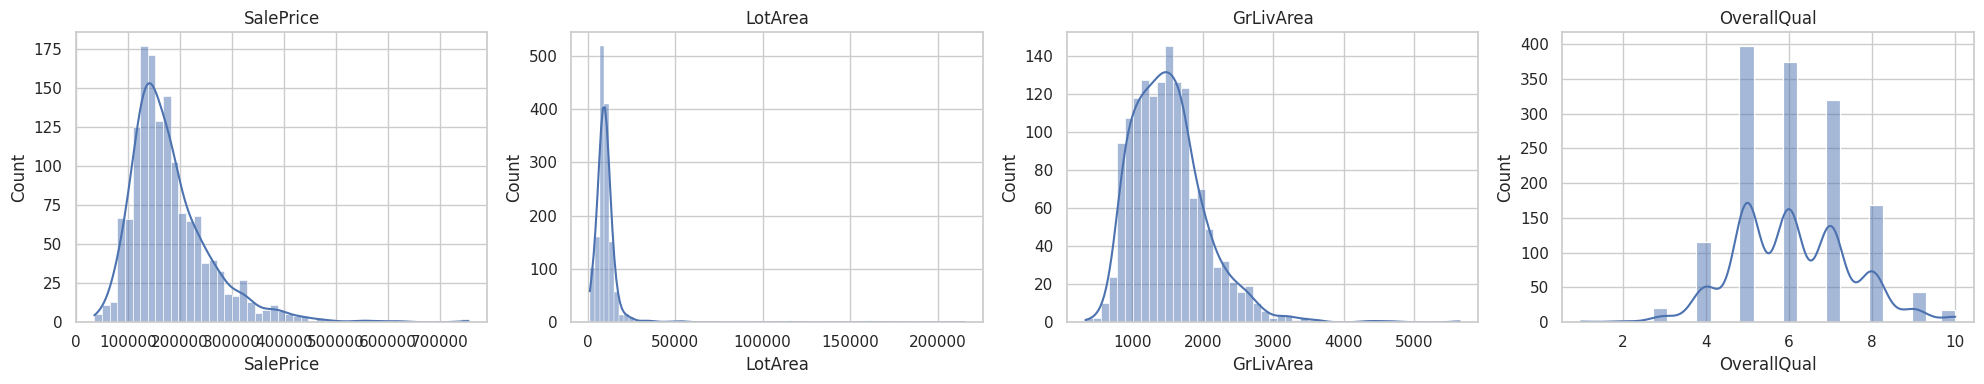

In [6]:
# Распределение целевой переменной
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")

# Три числовых признака для иллюстрации
hist_features = ["LotArea", "GrLivArea", "OverallQual"]
for ax, col in zip(axes[1:], hist_features):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Ваш ответ:** `MSSubClass` обычно имеет целочисленный тип (`int64`), но по смыслу это категориальный признак: числа 20, 30, 60 и т. д. обозначают тип здания/класс жилой застройки, а не количественную величину. Пример другого расхождения — `MoSold`: месяц продажи записан числом, но часто трактуется как циклическая категория (месяцы 1–12), а не как непрерывная величина. Также `OverallQual` хранится как число и действительно имеет упорядоченный смысл (качество от низкого к высокому).

## Часть 3. Обработка пропущенных значений (2 балла)

**Задание 3.1.** Посчитайте количество и долю пропусков в каждом столбце. Выведите топ-15 столбцов по доле пропусков в виде таблицы и/или столбчатой диаграммы.

,missing_count,missing_share
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageFinish,81,0.055479
GarageQual,81,0.055479
GarageYrBlt,81,0.055479
GarageType,81,0.055479


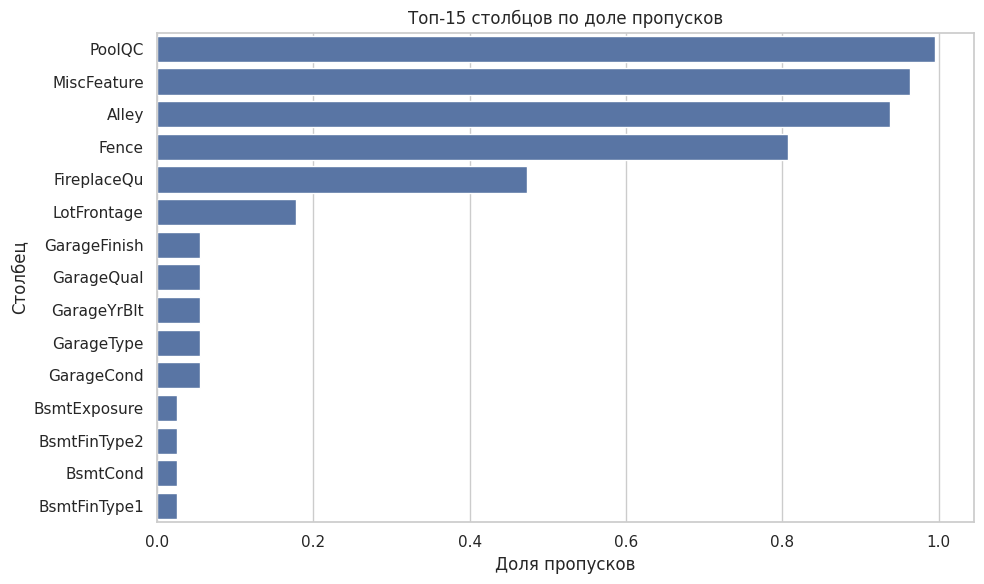

In [7]:
# Количество и доля пропусков по каждому столбцу
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_share": df.isna().mean()
}).sort_values("missing_share", ascending=False)
display(missing.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(data=missing.head(15).reset_index(), x="missing_share", y="index")
plt.xlabel("Доля пропусков")
plt.ylabel("Столбец")
plt.title("Топ-15 столбцов по доле пропусков")
plt.tight_layout()
plt.show()


**Ваш ответ:** В документации Ames Housing пропуски в `PoolQC`, `Alley`, `Fence` и `GarageType` означают, как правило, что у дома нет бассейна, подъезда/проезда соответствующего типа, забора или гаража. Это не обычное отсутствие измерения, а содержательная информация об отсутствии объекта. Если столбец сохраняется, такие пропуски разумно заменить отдельной категорией `"None"`, чтобы модель могла отличать отсутствие объекта от неизвестного значения. При этом по условию задания столбцы с долей пропусков более 40% удаляются — поэтому `PoolQC`, `Alley` и `Fence` (а также некоторые другие сильно разреженные столбцы) могут быть удалены до заполнения. Для оставшихся аналогичных признаков используем `"None"`.

**Задание 3.2.** Реализуйте обработку пропусков:
1. Удалите столбцы, где доля пропусков больше 40%.
2. Для **категориальных** признаков, где пропуск означает «отсутствие объекта» (гараж, подвал, забор и т.п.), заполните пропуски строкой `"None"`.
3. Для остальных **категориальных** признаков заполните пропуски модой.
4. Для **числовых** признаков заполните пропуски медианой.

После обработки убедитесь, что пропусков не осталось.

In [8]:
# 1. Удаляем столбцы, в которых пропущено более 40% значений
missing_share = df.isna().mean()
cols_to_drop = missing_share[missing_share > 0.40].index.tolist()
print("Удаляем столбцы:", cols_to_drop)
df = df.drop(columns=cols_to_drop)

# Обновляем списки признаков после удаления столбцов
numeric_features = df.select_dtypes(include=["number"]).columns.drop("SalePrice", errors="ignore").tolist()
categorical_features = df.select_dtypes(exclude=["number"]).columns.tolist()

# 2. Категориальные признаки, где NaN означает отсутствие объекта
absence_features = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature",
    "MasVnrType"
]
for col in categorical_features:
    if col in absence_features:
        df[col] = df[col].fillna("None")

# 3. Остальные категориальные пропуски заполняем модой
for col in categorical_features:
    if df[col].isna().any():
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

# 4. Числовые пропуски заполняем медианой
for col in numeric_features:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

print("Осталось пропусков:", int(df.isna().sum().sum()))
assert df.isna().sum().sum() == 0, "Остались пропуски!"


Удаляем столбцы: ['Alley', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
Осталось пропусков: 0


**Ваш ответ (вопрос 6):** Медиана устойчивее к выбросам и сильной асимметрии распределения. Несколько очень больших участков или дорогих домов могут заметно сдвинуть среднее, тогда как медиана почти не меняется. Среднее предпочтительнее, когда распределение приблизительно симметрично, не содержит сильных выбросов и пропуски можно считать случайными относительно значений признака.

**Ваш ответ (вопрос 7):** Допущена утечка данных (*data leakage*): статистики для заполнения пропусков вычислены с использованием будущей тестовой выборки. В результате информация о распределении test попадает в этап обучения, и оценка качества может стать оптимистичной. Правильно сначала разделить данные на train и test, затем обучать imputer только на train (`fit`), а к обеим выборкам применять одни и те же найденные параметры (`transform`). В `sklearn` для этого используют `SimpleImputer` внутри `Pipeline`/`ColumnTransformer`.

## Часть 4. Кодирование категориальных признаков: One-Hot vs Label Encoding (2 балла)

**Задание 4.1.** Выберите **один** категориальный признак с небольшим числом уникальных значений (например, `Street` или `CentralAir`). Примените к нему:
- Label Encoding (`sklearn.preprocessing.LabelEncoder`);
- One-Hot Encoding (`pd.get_dummies` или `sklearn.preprocessing.OneHotEncoder`).

Покажите результат каждого кодирования на нескольких первых строках.

In [9]:
feature = "Street"  # небольшой категориальный признак

# Label Encoding: каждой категории присваивается целочисленный код
label_encoder = LabelEncoder()
label_encoded = label_encoder.fit_transform(df[feature].astype(str))
label_result = pd.DataFrame({feature: df[feature], "label_encoded": label_encoded})
print("Label Encoding:")
display(label_result.head())
print("Соответствие кодов категориям:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

# One-Hot Encoding: отдельный бинарный столбец для каждой категории
onehot_result = pd.get_dummies(df[feature], prefix=feature, dtype=int)
print("One-Hot Encoding:")
display(onehot_result.head())


Label Encoding:


,Street,label_encoded
0,Pave,1
1,Pave,1
2,Pave,1
3,Pave,1
4,Pave,1


Соответствие кодов категориям: {'Grvl': np.int64(0), 'Pave': np.int64(1)}
One-Hot Encoding:


,Street_Grvl,Street_Pave
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


**Ваш ответ:** Label Encoding присваивает категориям числа и тем самым может неявно сообщить модели, что между ними есть порядок и расстояния (например, код 2 «больше» кода 1). Это допустимо для действительно упорядоченных категорий, например `OverallQual` (оценка качества) или `ExterQual` (`Po` < `Fa` < `TA` < `Gd` < `Ex`), если порядок задан осмысленно. Для номинальных категорий это вредно: например, `Neighborhood` или `Street` не имеют естественного числового порядка. Для таких признаков обычно используют One-Hot Encoding.

**Задание 4.2.** Примените One-Hot Encoding ко **всем** категориальным признакам датасета (`pd.get_dummies`). Сравните размер таблицы до и после кодирования.

In [10]:
# Кодируем все категориальные признаки; SalePrice оставляем отдельно
df_encoded = pd.get_dummies(df, columns=categorical_features, dtype=int)
print("Размер до кодирования:", df.shape)
print("Размер после кодирования:", df_encoded.shape)
print("Добавлено столбцов:", df_encoded.shape[1] - df.shape[1])
display(df_encoded.head())


Размер до кодирования: (1460, 76)
Размер после кодирования: (1460, 281)
Добавлено столбцов: 205


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,MSZoning_'C (all)',MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Grvl,Street_Pave,LotShape_IR1,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_Bnk,...,KitchenQual_Gd,KitchenQual_TA,Functional_Maj1,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Mod,Functional_Sev,Functional_Typ,GarageType_2Types,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_None,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Ex,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_Po,GarageQual_TA,GarageCond_Ex,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y,SaleType_COD,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,0,150,856,856,854,0,1710,1,0,2,1,3,1,8,0,2003.0,2,548,0,61,0,0,0,0,0,2,2008,208500,0,0,0,1,0,0,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,0,284,1262,1262,0,0,1262,0,1,2,0,3,1,6,1,1976.0,2,460,298,0,0,0,0,0,0,5,2007,181500,0,0,0,1,0,0,1,0,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,0,434,920,920,866,0,1786,1,0,2,1,3,1,6,1,2001.0,2,608,0,42,0,0,0,0,0,9,2008,223500,0,0,0,1,0,0,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,0,540,756,961,756,0,1717,1,0,1,0,3,1,7,1,1998.0,3,642,0,35,272,0,0,0,0,2,2006,140000,0,0,0,1,0,0,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,0,490,1145,1145,1053,0,2198,1,0,2,1,4,1,9,1,2000.0,3,836,192,84,0,0,0,0,0,12,2008,250000,0,0,0,1,0,0,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0


**Ваш ответ (вопрос 9):** Число столбцов увеличивается на сумму (число уникальных категорий признака минус один исходный столбец) по всем категориальным признакам; точное значение выводится в ячейке 4.2. Большое число столбцов увеличивает память и время вычислений, делает матрицу разреженной и может повысить риск переобучения, особенно при небольшом числе объектов. Число будущих столбцов заранее оценивают через `nunique()` для каждого категориального признака (с учётом параметра `drop` у кодировщика).

**Ваш ответ (вопрос 10):** При кодировании train и test независимо наборы столбцов могут различаться, и модель получит матрицы разной размерности. `OneHotEncoder(handle_unknown="ignore")` при встрече неизвестной категории не выдаёт ошибку: для неё соответствующий блок признаков будет заполнен нулями. Кодировщик нужно обучить на train и затем использовать для test через `transform`; обычно его помещают в `ColumnTransformer` внутри `Pipeline`.

## Часть 5. Нормализация числовых признаков (2 балла)

**Задание 5.1.** Возьмите числовые признаки (без `SalePrice`). Сравните два способа масштабирования:
- `StandardScaler` (z-нормализация);
- `MinMaxScaler` (приведение к отрезку [0, 1]).

Примените оба, сохраните результаты в отдельные DataFrame'ы и выведите статистики (`describe`) для трёх признаков до и после каждого масштабирования.

In [11]:
# Числовые признаки без целевой переменной
scale_features = [c for c in numeric_features if c != "SalePrice"]
X_numeric = df[scale_features].copy()

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
X_standard = pd.DataFrame(standard_scaler.fit_transform(X_numeric), columns=scale_features, index=df.index)
X_minmax = pd.DataFrame(minmax_scaler.fit_transform(X_numeric), columns=scale_features, index=df.index)

selected_for_describe = [c for c in ["LotArea", "GrLivArea", "OverallQual"] if c in scale_features]
print("Исходные данные:")
display(X_numeric[selected_for_describe].describe())
print("После StandardScaler:")
display(X_standard[selected_for_describe].describe())
print("После MinMaxScaler:")
display(X_minmax[selected_for_describe].describe())


Исходные данные:


,LotArea,GrLivArea,OverallQual
count,1460.000000,1460.000000,1460.000000
mean,10516.828082,1515.463699,6.099315
std,9981.264932,525.480383,1.382997
min,1300.000000,334.000000,1.000000
25%,7553.500000,1129.500000,5.000000
50%,9478.500000,1464.000000,6.000000
75%,11601.500000,1776.750000,7.000000
max,215245.000000,5642.000000,10.000000


После StandardScaler:


,LotArea,GrLivArea,OverallQual
count,1.460000e+03,1.460000e+03,1.460000e+03
mean,-5.840077e-17,-1.277517e-16,1.387018e-16
std,1.000343e+00,1.000343e+00,1.000343e+00
min,-9.237292e-01,-2.249120e+00,-3.688413e+00
25%,-2.969908e-01,-7.347485e-01,-7.951515e-01
50%,-1.040633e-01,-9.797004e-02,-7.183611e-02
75%,1.087080e-01,4.974036e-01,6.514792e-01
max,2.051827e+01,7.855574e+00,2.821425e+00


После MinMaxScaler:


,LotArea,GrLivArea,OverallQual
count,1460.000000,1460.000000,1460.000000
mean,0.043080,0.222582,0.566591
std,0.046653,0.098998,0.153666
min,0.000000,0.000000,0.000000
25%,0.029229,0.149868,0.444444
50%,0.038227,0.212886,0.555556
75%,0.048150,0.271807,0.666667
max,1.000000,1.000000,1.000000


**Задание 5.2.** Для **одного** числового признака на ваш выбор постройте три гистограммы рядом (исходное распределение, после `StandardScaler`, после `MinMaxScaler`).

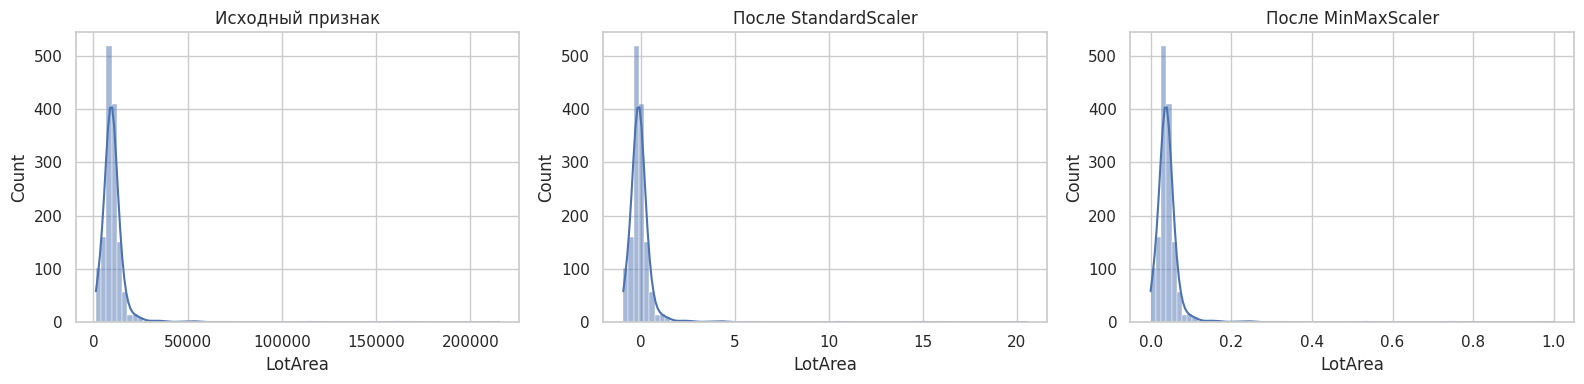

In [12]:
feature_to_plot = "LotArea"
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df[feature_to_plot], kde=True, ax=axes[0])
axes[0].set_title("Исходный признак")
sns.histplot(X_standard[feature_to_plot], kde=True, ax=axes[1])
axes[1].set_title("После StandardScaler")
sns.histplot(X_minmax[feature_to_plot], kde=True, ax=axes[2])
axes[2].set_title("После MinMaxScaler")
plt.tight_layout()
plt.show()


**Ваш ответ:** Линейное масштабирование не меняет форму распределения: сохраняются порядок наблюдений, относительная асимметрия и наличие выбросов. Меняются только шкала, положение и масштаб: `StandardScaler` центрирует данные и делит на стандартное отклонение, а `MinMaxScaler` линейно переводит минимум в 0, максимум в 1. При сильной асимметрии и выбросах сильнее страдает `MinMaxScaler`: экстремальные значения определяют минимум и максимум, поэтому основная масса наблюдений сжимается в узкий интервал. `StandardScaler` тоже чувствителен к выбросам, поскольку среднее и стандартное отклонение неустойчивы к ним, но не ограничивает все значения интервалом [0, 1].

## Часть 6. Обучение kNN и сравнение способов предобработки (2 балла)

В этой части мы наконец обучим модель. Исходная задача — регрессия (цена — непрерывная величина), поэтому для классификационного kNN превратим её в бинарную: будем предсказывать, **дорогой ли дом** (цена выше медианы).

**Задание 6.1.** Подготовьте данные:
1. Создайте бинарную целевую переменную `y`: 1, если `SalePrice` выше медианы, иначе 0.
2. Соберите матрицу признаков `X`: числовые признаки + one-hot закодированные категориальные (как в задании 4.2). Целевую переменную в признаки не включайте.
3. Разделите данные на обучающую и тестовую выборки (`train_test_split`, `test_size=0.25`, `random_state=42`, `stratify=y`).

In [13]:
from sklearn.model_selection import train_test_split

# Бинарная цель: 1 — цена выше медианы, 0 — иначе
y = (df["SalePrice"] > df["SalePrice"].median()).astype(int)

# Признаки: числовые + one-hot категориальные; ID исключаем как технический идентификатор
X_base = df.drop(columns=["SalePrice", "Id"], errors="ignore")
X = pd.get_dummies(X_base, columns=[c for c in X_base.columns if X_base[c].dtype == "object" or str(X_base[c].dtype).startswith("category")], dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (1095, 279) Test: (365, 279)


**Задание 6.2.** Обучите `KNeighborsClassifier` с `n_neighbors=5` и посчитайте accuracy на тестовой выборке для **трёх** вариантов предобработки числовых признаков:
- без масштабирования;
- со `StandardScaler`;
- с `MinMaxScaler`.

*Подсказка:* скейлер обучайте (`fit`) только на train-части, а к test применяйте `transform`. Для наглядности соберите результаты в маленькую таблицу.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Масштабируем только числовые колонки, one-hot признаки оставляем бинарными
model_numeric = [c for c in scale_features if c in X_train.columns and c != "Id"]
results = []

# Без масштабирования
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)
results.append({"Предобработка": "Без масштабирования", "Accuracy": accuracy_score(y_test, pred)})

# StandardScaler: fit только на train
scaler_std = StandardScaler()
X_train_std, X_test_std = X_train.copy(), X_test.copy()
X_train_std[model_numeric] = scaler_std.fit_transform(X_train[model_numeric])
X_test_std[model_numeric] = scaler_std.transform(X_test[model_numeric])
knn_std = KNeighborsClassifier(n_neighbors=5).fit(X_train_std, y_train)
pred_std = knn_std.predict(X_test_std)
results.append({"Предобработка": "StandardScaler", "Accuracy": accuracy_score(y_test, pred_std)})

# MinMaxScaler: fit только на train
scaler_mm = MinMaxScaler()
X_train_mm, X_test_mm = X_train.copy(), X_test.copy()
X_train_mm[model_numeric] = scaler_mm.fit_transform(X_train[model_numeric])
X_test_mm[model_numeric] = scaler_mm.transform(X_test[model_numeric])
knn_mm = KNeighborsClassifier(n_neighbors=5).fit(X_train_mm, y_train)
pred_mm = knn_mm.predict(X_test_mm)
results.append({"Предобработка": "MinMaxScaler", "Accuracy": accuracy_score(y_test, pred_mm)})

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results_df)
best_preprocessing = results_df.loc[0, "Предобработка"]
print("Лучший вариант по accuracy на test:", best_preprocessing)


,Предобработка,Accuracy
0,StandardScaler,0.906849
1,MinMaxScaler,0.868493
2,Без масштабирования,0.819178


Лучший вариант по accuracy на test: StandardScaler


**Ваш ответ:** Конкретный лучший и худший варианты определяются по таблице, полученной в задании 6.2; заранее приписывать им численные значения нельзя. kNN основан на расстояниях между объектами. В евклидовой метрике квадрат разности по каждому признаку входит в общую сумму. Поэтому признак с большим численным диапазоном (например, `LotArea` в квадратных футах) может доминировать над признаком `OverallQual` со значениями примерно от 1 до 10. Масштабирование приводит признаки к сопоставимым шкалам и позволяет учитывать их совместный вклад.

**Задание 6.3.** Для лучшего варианта предобработки из задания 6.2 подберите число соседей: переберите `n_neighbors` от 1 до 30, обучите kNN для каждого значения и постройте график зависимости accuracy на train и на test от $k$. Чему равно лучшее $k$?

Лучшее k по accuracy на test: 17
Accuracy на test: 0.9205479452054794


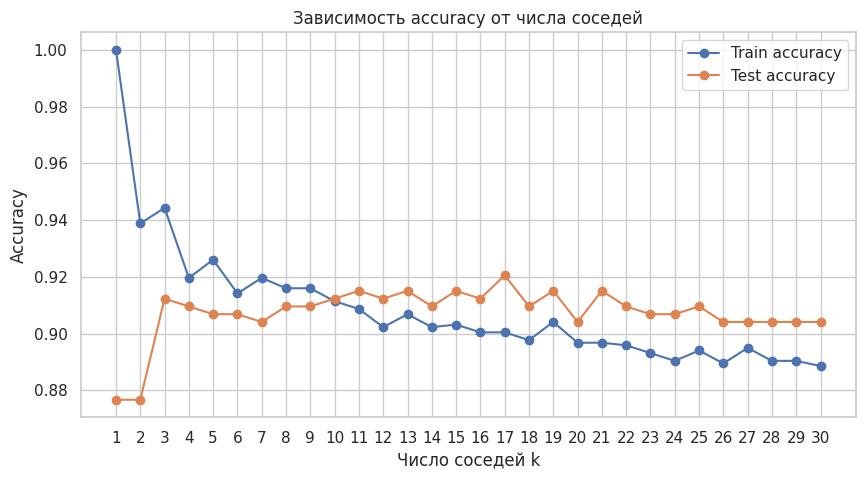

In [15]:
# Выбираем лучший вариант из сравнения выше и исследуем k=1,...,30
if best_preprocessing == "StandardScaler":
    Xtr_best, Xte_best = X_train_std, X_test_std
elif best_preprocessing == "MinMaxScaler":
    Xtr_best, Xte_best = X_train_mm, X_test_mm
else:
    Xtr_best, Xte_best = X_train, X_test

k_values = range(1, 31)
train_accuracy, test_accuracy = [], []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(Xtr_best, y_train)
    train_accuracy.append(accuracy_score(y_train, model.predict(Xtr_best)))
    test_accuracy.append(accuracy_score(y_test, model.predict(Xte_best)))

best_index = int(np.argmax(test_accuracy))
best_k = list(k_values)[best_index]
print("Лучшее k по accuracy на test:", best_k)
print("Accuracy на test:", test_accuracy[best_index])

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_accuracy, marker="o", label="Train accuracy")
plt.plot(k_values, test_accuracy, marker="o", label="Test accuracy")
plt.xlabel("Число соседей k")
plt.ylabel("Accuracy")
plt.title("Зависимость accuracy от числа соседей")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()


**Ваш ответ (вопрос 13):** Переобучение обычно наблюдается при очень малых `k`: граница решения становится сложной, train accuracy близка к 1, а test accuracy заметно ниже. Недообучение проявляется при слишком больших `k`: модель чрезмерно сглаживает границу, и качество низкое как на train, так и на test. Оптимальное значение выбирают в области максимума качества на отложенной валидационной выборке, а не по тесту. Конкретные интервалы и лучшее `k` нужно определить по построенному графику.

**Ваш ответ (вопрос 14):** Утечки: (1) медианы и моды для заполнения пропусков считались до разделения; (2) параметры масштабирования в частях 5.1–5.2 считались по всему датасету; (3) выбор лучшего scaler и `k` по результатам на test использует тестовую выборку для настройки модели. Корректный порядок: сначала отделить test; все преобразования обучать только на train; для подбора гиперпараметров использовать кросс-валидацию внутри train; test открыть один раз для финальной оценки. В `sklearn` это реализуется через `SimpleImputer`, `StandardScaler`/`MinMaxScaler`, `OneHotEncoder(handle_unknown="ignore")`, `ColumnTransformer`, `Pipeline`, `GridSearchCV` (или `RandomizedSearchCV`) и `train_test_split`. В идеале `GridSearchCV` подбирает scaler/параметры kNN по CV, а итоговый `Pipeline` оценивается на нетронутом test.